# CIDDS-001 Network Anomaly Detection with a Heterogeneous GNN

A memory-conscious graph learning experiment for classifying network flows as **benign**, **brute-force**, **DoS**, **ping scan**, or **port scan** using the CIDDS-001 internal week-1 traffic capture.

The model represents each flow and host as separate node types, connects source and destination hosts to flow nodes, and uses GraphSAGE message passing to predict a flow's attack class. The preprocessing pipeline is designed for the dataset's 8.4 million rows and reduces memory use with selected columns, compact dtypes, and batched subgraphs.

**Saved test-set benchmark:** 99.99% accuracy and 0.9747 macro F1 across 844,800 flows. This is a random row-level split; it does not establish performance on later time periods or unseen networks. See the evaluation notes and limitations below.

> Run from the repository root. The notebook downloads the CIDDS-001 archive when the expected CSV is not present.

In [ ]:
%pip install -q -r requirements.txt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.2 MB/s eta 0:00:00


In [ ]:
import gc, os, urllib.request, zipfile
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.optim import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from torch_geometric.loader import DataLoader
from torch_geometric.data import HeteroData

## 1. Download and load the data

The archive is downloaded once and the CSV is read using only the fields used by the model. The dataset itself is excluded from version control.

In [ ]:
# Download to disk instead of holding the whole zip in RAM
CSV_PATH = "CIDDS-001/traffic/OpenStack/CIDDS-001-internal-week1.csv"
url = "https://www.hs-coburg.de/wp-content/uploads/2024/11/CIDDS-001.zip"
if not os.path.exists(CSV_PATH):
    urllib.request.urlretrieve(url, "CIDDS-001.zip")
    with zipfile.ZipFile("CIDDS-001.zip") as z:
        z.extractall(".")
    os.remove("CIDDS-001.zip")

In [ ]:
# Load only the columns we use, with compact dtypes (strings -> category)
usecols = ["Date first seen", "Duration", "Proto", "Src IP Addr", "Dst IP Addr",
           "Packets", "Bytes", "Flags", "attackType"]
df = pd.read_csv(
    CSV_PATH,
    usecols=usecols,
    dtype={"Duration": "float32", "Packets": "int32", "Bytes": "str",
           "Proto": "category", "Flags": "category", "attackType": "category",
           "Src IP Addr": "category", "Dst IP Addr": "category"},
    parse_dates=["Date first seen"],
)
print(df.shape)
print(f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB in RAM")
print(df["attackType"].value_counts(normalize=True).mul(100).round(2))

(8451520, 9)
0.68 GB in RAM
attackType
---           82.95
dos           14.82
portScan       2.17
pingScan       0.04
bruteForce     0.02
Name: proportion, dtype: float64


## 2. Engineer flow and host features

Flow features combine time, traffic volume, TCP flags, and protocol. Each distinct source or destination address is represented as a host node with a compact 16-bit feature vector.

In [ ]:
labels = ["benign", "bruteForce", "dos", "pingScan", "portScan"]

# ---- labels: integer class ids (no one-hot frame, no multi-column stratify) ----
atk = df["attackType"].cat.rename_categories(lambda c: "benign" if c.strip() == "---" else c.strip())
y = atk.cat.set_categories(labels).cat.codes.to_numpy().astype(np.int64)
assert (y >= 0).all(), "unexpected attackType value"

# ---- Bytes: values like '2.9 M' -> numbers (only the non-numeric rows go through the parser) ----
def parse_human_bytes(val):
    s = str(val).strip().upper()
    mult = {"K": 1e3, "M": 1e6, "G": 1e9}.get(s[-1:], 1)
    if mult != 1:
        s = s[:-1].strip()
    try:
        return float(s) * mult
    except ValueError:
        return 0.0

bytes_num = pd.to_numeric(df["Bytes"], errors="coerce")
bad = bytes_num.isna()
bytes_num.loc[bad] = df.loc[bad, "Bytes"].map(parse_human_bytes)
bytes_num = bytes_num.to_numpy(np.float64)

# ---- time features ----
t = df["Date first seen"]
days = np.eye(7, dtype=np.float32)[t.dt.weekday.to_numpy()][:, :5]          # Mon..Fri, as in the original
daytime = ((t.dt.hour * 3600 + t.dt.minute * 60 + t.dt.second) / 86400).to_numpy(np.float32)

# ---- TCP flags (ACK, PSH, RST, SYN, FIN): build per distinct flag string, then look up by code ----
flag_cats = df["Flags"].cat.categories
flag_table = np.array([[int(c == ch) for ch, c in zip("APRSF", s[1:])] for s in flag_cats], dtype=np.float32)
flags = flag_table[df["Flags"].cat.codes.to_numpy()]

# ---- protocol one-hot ----
proto_names = df["Proto"].cat.categories.astype(str).tolist()
proto = np.eye(len(proto_names), dtype=np.float32)[df["Proto"].cat.codes.to_numpy()]
flow_feature_names = (
    ["time_of_day"]
    + [f"weekday_{day}" for day in ["mon", "tue", "wed", "thu", "fri"]]
    + ["duration", "packets", "bytes"]
    + ["flag_ack", "flag_psh", "flag_rst", "flag_syn", "flag_fin"]
    + [f"proto_{name}" for name in proto_names]
)

# ---- hosts: one integer id per distinct IP, plus one 16-bit feature vector per host ----
src_cat, dst_cat = df["Src IP Addr"].cat, df["Dst IP Addr"].cat
all_ips = pd.Index(src_cat.categories).union(pd.Index(dst_cat.categories))
src_id = all_ips.get_indexer(src_cat.categories)[src_cat.codes.astype(np.int64)]
dst_id = all_ips.get_indexer(dst_cat.categories)[dst_cat.codes.astype(np.int64)]

octets = all_ips.to_series().astype(str).str.extract(r"^\d{1,3}\.\d{1,3}\.(\d{1,3})\.(\d{1,3})$")
ip16 = (octets[0].fillna(0).astype(np.int32).to_numpy() << 8) | octets[1].fillna(0).astype(np.int32).to_numpy()
ip_bits = ((ip16[:, None] >> np.arange(15, -1, -1)) & 1).astype(np.float32)   # (n_hosts, 16)
print("distinct hosts:", len(all_ips))

# ---- continuous columns, then free the big DataFrame ----
cont = np.column_stack([df["Duration"].to_numpy(np.float64),
                        df["Packets"].to_numpy(np.float64),
                        bytes_num])
del df, atk, t, bytes_num, bad, octets
gc.collect()

distinct hosts: 10108


73

## 3. Split and transform

The stratified split keeps class proportions similar across train, validation, and test sets. The power transform is fitted only on a sample from the training split.

In [ ]:
# Split by row index (stratified on the 1-D class id), fit the scaler on train only
idx = np.arange(len(y))
idx_train, idx_tmp = train_test_split(idx, test_size=0.2, random_state=0, stratify=y)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, random_state=0, stratify=y[idx_tmp])

scaler = PowerTransformer()
fit_idx = np.random.default_rng(0).choice(idx_train, size=min(1_000_000, len(idx_train)), replace=False)
scaler.fit(cont[fit_idx])                       # Yeo-Johnson fit on a 1M-row train sample
cont = scaler.transform(cont).astype(np.float32)

X = np.concatenate([daytime[:, None], days, cont, flags, proto], axis=1)   # flow features, float32
del cont, daytime, days, flags, proto
gc.collect()
print("flow features:", X.shape, "| host features:", ip_bits.shape)

flow features: (8451520, 18) | host features: (10108, 16)


## 4. Build heterogeneous subgraphs

Each mini-batch contains independent subgraphs of host and flow nodes. This bounds graph memory while retaining each flow's source and destination relationships.

In [ ]:
BATCH_SIZE = 16

def create_dataloader(idx, subgraph_size=1024):
    X_s, y_s, src_s, dst_s = X[idx], y[idx], src_id[idx], dst_id[idx]
    onehot = np.eye(len(labels), dtype=np.float32)
    flow_idx = np.arange(subgraph_size)
    data = []
    for i in range(len(idx) // subgraph_size):
        sl = slice(i * subgraph_size, (i + 1) * subgraph_size)

        # local host index (0..n_hosts_in_subgraph-1) for every src/dst endpoint
        hosts, inv = np.unique(np.concatenate([src_s[sl], dst_s[sl]]), return_inverse=True)
        h2f = np.stack([inv.reshape(-1), np.concatenate([flow_idx, flow_idx])]).astype(np.int64)
        f2h = np.ascontiguousarray(h2f[::-1])

        g = HeteroData()
        g["host"].x = torch.from_numpy(ip_bits[hosts])        # one row per host in this subgraph
        g["flow"].x = torch.from_numpy(X_s[sl])
        g["flow"].y = torch.from_numpy(onehot[y_s[sl]])
        g["host", "flow"].edge_index = torch.from_numpy(h2f)
        g["flow", "host"].edge_index = torch.from_numpy(f2h)
        data.append(g)
    return DataLoader(data, batch_size=BATCH_SIZE)

train_loader = create_dataloader(idx_train)
val_loader = create_dataloader(idx_val)
test_loader = create_dataloader(idx_test)

## 5. Train the model

The model applies three rounds of GraphSAGE message passing between hosts and flows. Validation macro F1 is printed every ten epochs; the saved test report below uses the held-out test split.

In [ ]:
from torch_geometric.nn import Linear, HeteroConv, SAGEConv

# Redefining the HeteroGNN class without the deprecated 'add_self_loops' argument
class HeteroGNN(torch.nn.Module):
    def __init__(self, dim_h, dim_out, num_layers):
        super().__init__()

        self.convs = torch.nn.ModuleList()
        for _ in range(num_layers):
            conv = HeteroConv({
                ('host', 'to', 'flow'): SAGEConv((-1,-1), dim_h),
                ('flow', 'to', 'host'): SAGEConv((-1,-1), dim_h),
            }, aggr='sum')
            self.convs.append(conv)

        self.lin = Linear(dim_h, dim_out)

    def forward(self, x_dict, edge_index_dict):
        for conv in self.convs:
            x_dict = conv(x_dict, edge_index_dict)
            x_dict = {key: F.leaky_relu(x) for key, x in x_dict.items()}
        return self.lin(x_dict['flow'])

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = HeteroGNN(dim_h=64, dim_out=5, num_layers=3).to(device)
optimizer = Adam(model.parameters(), lr=0.001)

@torch.no_grad()
def test(loader):
    model.eval()
    y_pred = []
    y_true = []
    n_subgraphs = 0
    total_loss = 0

    for batch in loader:
        batch.to(device)
        out = model(batch.x_dict, batch.edge_index_dict)
        loss = F.cross_entropy(out, batch['flow'].y.float())
        y_pred.append(out.argmax(dim=1))
        y_true.append(batch['flow'].y.argmax(dim=1))
        n_subgraphs += BATCH_SIZE
        total_loss += float(loss) * BATCH_SIZE

    y_pred = torch.cat(y_pred).cpu()
    y_true = torch.cat(y_true).cpu()
    f1score = f1_score(y_true, y_pred, average='macro')

    return total_loss/n_subgraphs, f1score, y_pred, y_true

model.train()
for epoch in range(101):
    n_subgraphs = 0
    total_loss = 0

    for batch in train_loader:
        optimizer.zero_grad()
        batch.to(device)
        out = model(batch.x_dict, batch.edge_index_dict)
        loss = F.cross_entropy(out, batch['flow'].y.float())
        loss.backward()
        optimizer.step()

        n_subgraphs += BATCH_SIZE
        total_loss += float(loss) * BATCH_SIZE

    if epoch % 10 == 0:
        val_loss, f1score, _, _ = test(val_loader)
        print(f'Epoch {epoch} | Loss: {total_loss/n_subgraphs:.4f} | Val loss: {val_loss:.4f} | Val F1-score: {f1score:.4f}')

/tmp/ipykernel_1408/1060643370.py:65: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  total_loss += float(loss) * BATCH_SIZE


Epoch 0 | Loss: 0.0850 | Val loss: 0.0023 | Val F1-score: 0.7440
Epoch 10 | Loss: 0.0006 | Val loss: 0.0005 | Val F1-score: 0.9521
Epoch 20 | Loss: 0.0004 | Val loss: 0.0004 | Val F1-score: 0.9570
Epoch 30 | Loss: 0.0004 | Val loss: 0.0004 | Val F1-score: 0.9489
Epoch 40 | Loss: 0.0003 | Val loss: 0.0003 | Val F1-score: 0.9651
Epoch 50 | Loss: 0.0002 | Val loss: 0.0002 | Val F1-score: 0.9899
Epoch 60 | Loss: 0.0001 | Val loss: 0.0001 | Val F1-score: 0.9919
Epoch 70 | Loss: 0.0001 | Val loss: 0.0001 | Val F1-score: 0.9945
Epoch 80 | Loss: 0.0001 | Val loss: 0.0001 | Val F1-score: 0.9975
Epoch 90 | Loss: 0.0001 | Val loss: 0.0001 | Val F1-score: 0.9900
Epoch 100 | Loss: 0.0001 | Val loss: 0.0003 | Val F1-score: 0.9815


## 6. Evaluate on the test split

The class report includes per-class precision, recall, F1, and support. Read it alongside the confusion matrix: the test set is imbalanced, and aggregate accuracy hides performance differences on rare attacks.

In [ ]:
_, _, y_pred, y_true = test(test_loader)

print(classification_report(y_true, y_pred, target_names=labels, digits=4))

              precision    recall  f1-score   support

      benign     1.0000    1.0000    1.0000    700801
  bruteForce     0.9360    0.9877    0.9612       163
         dos     1.0000    1.0000    1.0000    125158
    pingScan     0.8791    0.9524    0.9143       336
    portScan     0.9990    0.9974    0.9982     18342

    accuracy                         0.9999    844800
   macro avg     0.9628    0.9875    0.9747    844800
weighted avg     0.9999    0.9999    0.9999    844800



## 7. Explain one test prediction

After training, this cell explains one flow from the held-out test data with Integrated Gradients. It reports influential flow features and host-flow edges. These are model attributions, not causal explanations.

In [ ]:
from torch_geometric.explain import CaptumExplainer, Explainer

example_graph = test_loader.dataset[0].to(device)
flow_index = 0
model.eval()

explainer = Explainer(
    model=model,
    algorithm=CaptumExplainer("IntegratedGradients"),
    explanation_type="model",
    node_mask_type="attributes",
    edge_mask_type="object",
    model_config=dict(
        mode="multiclass_classification",
        task_level="node",
        return_type="raw",
    ),
)

explanation = explainer(
    example_graph.x_dict,
    example_graph.edge_index_dict,
    index=flow_index,
)

with torch.no_grad():
    flow_logits = model(example_graph.x_dict, example_graph.edge_index_dict)[flow_index]

predicted_class = int(flow_logits.argmax())
true_class = int(example_graph["flow"].y[flow_index].argmax())
print(f"Predicted: {labels[predicted_class]} | Actual: {labels[true_class]}")

flow_scores = explanation.node_mask_dict["flow"][flow_index].abs().detach().cpu()
top_indices = flow_scores.topk(min(10, flow_scores.numel())).indices.tolist()
display(pd.DataFrame({
    "feature": [flow_feature_names[index] for index in top_indices],
    "importance": [flow_scores[index].item() for index in top_indices],
}))

edge_rows = []
for edge_type, edge_mask in explanation.edge_mask_dict.items():
    edge_index = example_graph[edge_type].edge_index
    incident = edge_index[0] == flow_index if edge_type[0] == "flow" else edge_index[1] == flow_index
    for edge_position in torch.where(incident)[0].tolist():
        host_index = edge_index[1, edge_position] if edge_type[0] == "flow" else edge_index[0, edge_position]
        edge_rows.append({
            "relation": " -> ".join(edge_type),
            "local_host_node": int(host_index),
            "importance": float(edge_mask[edge_position].detach().cpu()),
        })
display(pd.DataFrame(edge_rows).sort_values("importance", ascending=False))

### Error breakdown

The pie chart shows each true class's share of all incorrect predictions, not that class's error rate. The normalized confusion matrix below gives the per-class error pattern.

([<matplotlib.patches.Wedge at 0x7f2fea8e2510>,
 [Text(-0.2506388542933715, 1.0710649675526254, 'benign'),
  Text(-0.5254917825650289, -0.9663634856805323, 'bruteForce'),
  Text(0.6668482759501705, -0.8748219115124436, 'dos'),
  Text(1.0606789183642598, -0.29147938544196256, 'pingScan'),
  Text(1.096772420817562, -0.08420366342377766, 'portScan')],
 [Text(-0.136712102341839, 0.5842172550287047, '57%'),
  Text(-0.28663188139910667, -0.5271073558257449, '20%'),
  Text(0.3637354232455475, -0.47717558809769645, '17%'),
  Text(0.5785521372895962, -0.1589887556956159, '4%'),
  Text(0.5982395022641247, -0.045929270958424175, '2%')])

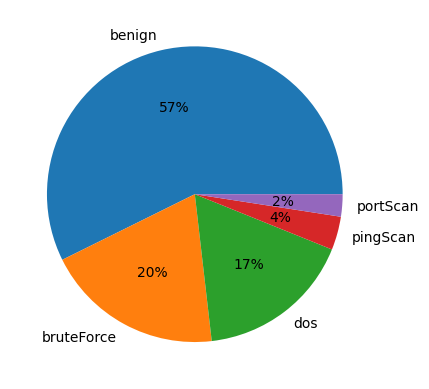

In [ ]:
import matplotlib.pyplot as plt
df_pred = pd.DataFrame([y_pred.numpy(), y_true.numpy()]).T
df_pred.columns = ['pred', 'true']
plt.pie(df_pred['true'][df_pred['pred'] != df_pred['true']].value_counts(), labels=labels, autopct='%.0f%%')

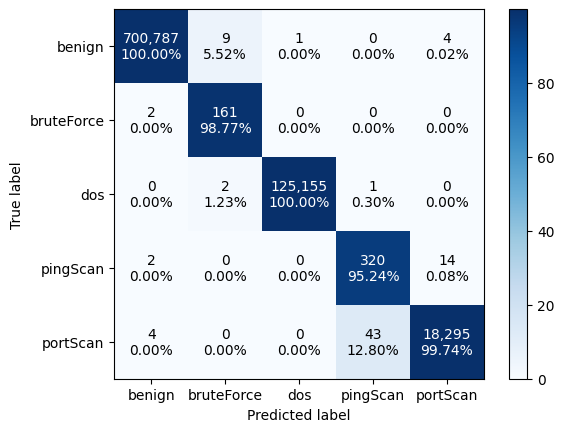

In [ ]:
import itertools
matrix = confusion_matrix(y_true, y_pred)
norm_matrix = matrix / matrix.sum(axis=1) * 100

plt.imshow(norm_matrix, cmap='Blues')
plt.colorbar()
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)

for i, j in itertools.product(range(matrix.shape[0]), range(matrix.shape[1])):
    text = f"{matrix[i,j]:,}\n{norm_matrix[i,j]:.2f}%"
    plt.text(j, i, text,
            horizontalalignment='center', verticalalignment='center',
            color='white' if matrix[i,j] >= matrix[i,:].mean() else 'black')
plt.show()